In [39]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Thu May 28 18:51:54 2026

@author: jeferson
"""

# ==========================================
# GENERAL IMPORTS
# ==========================================
import warnings
warnings.filterwarnings("ignore")
from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning
warnings.simplefilter('ignore', ConvergenceWarning)
warnings.simplefilter('ignore', ValueWarning)
warnings.simplefilter('ignore', UserWarning)

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Statsmodels & Time Series
import statsmodels as ss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import month_plot, plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tools.eval_measures import mse

# Deep Learning & ML
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
tf.keras.backend.clear_session() 

np.random.seed(0)
tf.random.set_seed(0)

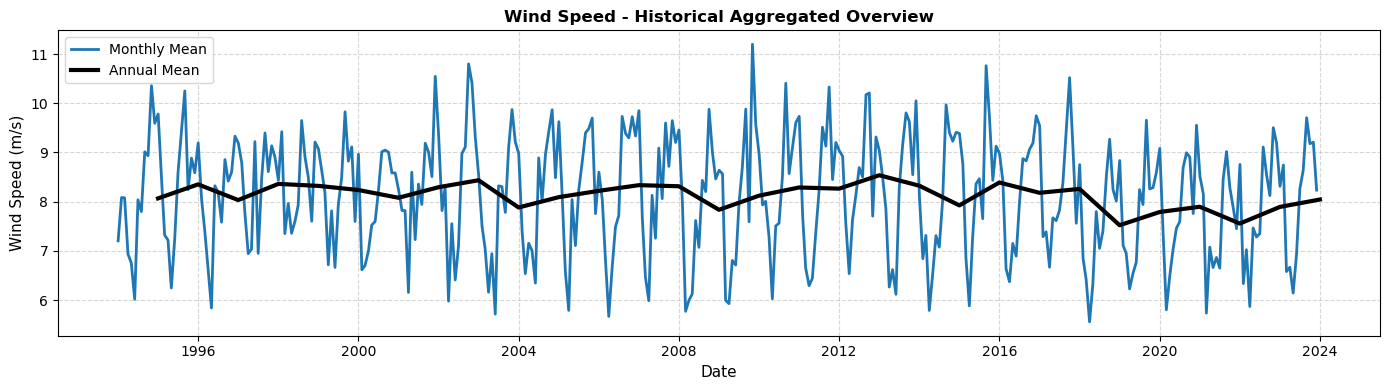

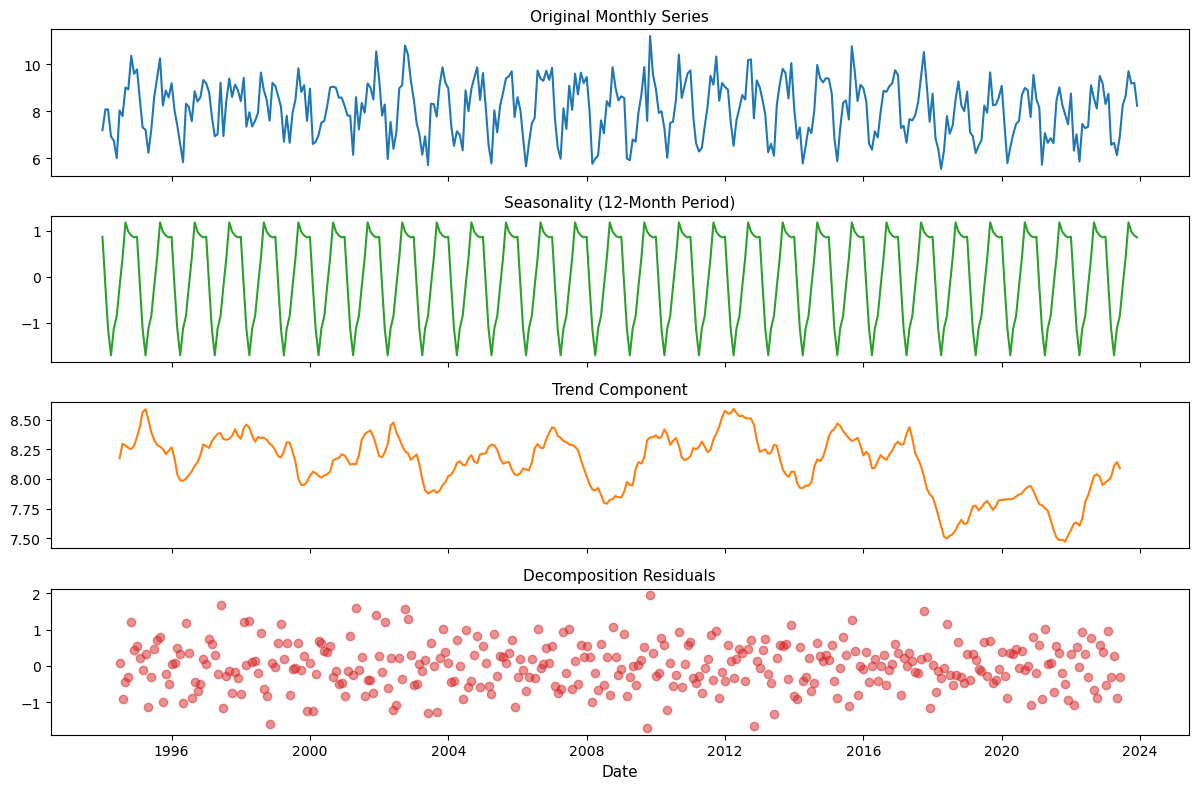

In [40]:
# ==========================================
# 1. DATA LOADING AND EXPLORATORY ANALYSIS
# ==========================================

# 1.1 Dataset Loading
file_path = '/home/jeferson/Documentos/Data Sciense para Energia/Algorithms/datasets/albacora_wind_30anos.csv'
wind_speed = pd.read_csv(file_path, skipfooter=2, header=0, index_col=0,   
                         names=['time', 'wind_speed'], engine='python')
wind_speed.index = pd.to_datetime(wind_speed.index)

# 1.2 Resampling & Missing Values Imputation
monthly_wind = wind_speed.resample('MS').mean()
monthly_wind.index.name = 'month'
monthly_wind['wind_speed'] = monthly_wind['wind_speed'].interpolate(method='linear')

annual_wind = wind_speed.resample('YE').mean()
annual_wind.index.name = 'year'

# 1.3 Plot: Overview of Monthly and Annual Aggregations
plt.figure(figsize=(14, 4))
plt.plot(monthly_wind.index, monthly_wind['wind_speed'], label="Monthly Mean", linewidth=2, color='tab:blue')
plt.plot(annual_wind.index, annual_wind['wind_speed'], label="Annual Mean", linewidth=3, color='black')
plt.title("Wind Speed - Historical Aggregated Overview", fontsize=12, fontweight='bold')
plt.xlabel("Date", fontsize=11)
plt.ylabel("Wind Speed (m/s)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# 1.4 Plot: Seasonal Decomposition
decomposition = seasonal_decompose(x=monthly_wind['wind_speed'], model='additive', period=12)
fig, axs = plt.subplots(4, 1, sharex=True, figsize=(12, 8))
axs[0].plot(monthly_wind.index, monthly_wind['wind_speed'], color='tab:blue')
axs[0].set_title('Original Monthly Series', fontsize=11)
axs[1].plot(decomposition.seasonal.index, decomposition.seasonal, color='tab:green')
axs[1].set_title('Seasonality (12-Month Period)', fontsize=11)
axs[2].plot(decomposition.trend.index, decomposition.trend, color='tab:orange')
axs[2].set_title('Trend Component', fontsize=11)
axs[3].plot(decomposition.resid.index, decomposition.resid, color='tab:red', linestyle='none', marker='o', alpha=0.5)
axs[3].set_title('Decomposition Residuals', fontsize=11)
plt.xlabel("Date", fontsize=11)
plt.tight_layout()
plt.show()

# ==========================================
# 1.5 PREPARATION FOR PREDICTIVE MODELS
# ==========================================
# Creating the seasonally differenced series to feed the models
monthly_wind['Seasonally_Differenced'] = monthly_wind['wind_speed'].diff(12)
monthly_wind_clean = monthly_wind.dropna()

# Strict configuration of the 36-month validation horizon
test_size = 36
train_size = len(monthly_wind_clean) - test_size

# Splitting train and test datasets as Pandas objects to preserve DatetimeIndex
train_series = monthly_wind_clean['Seasonally_Differenced'][:-test_size]
test_series = monthly_wind_clean['Seasonally_Differenced'][-test_size:]

# Generating scale-reversion variables to prevent future broadcast shape ValueErrors
historical_baseline = monthly_wind['wind_speed'].shift(12).loc[test_series.index]
test_actual_scale = monthly_wind['wind_speed'].loc[test_series.index].values
train_actual_scale = monthly_wind['wind_speed'].iloc[:train_size + 12].values # +12 offsets the initial dropped seasonal rows


--- Plotting Identification Diagnostics ---


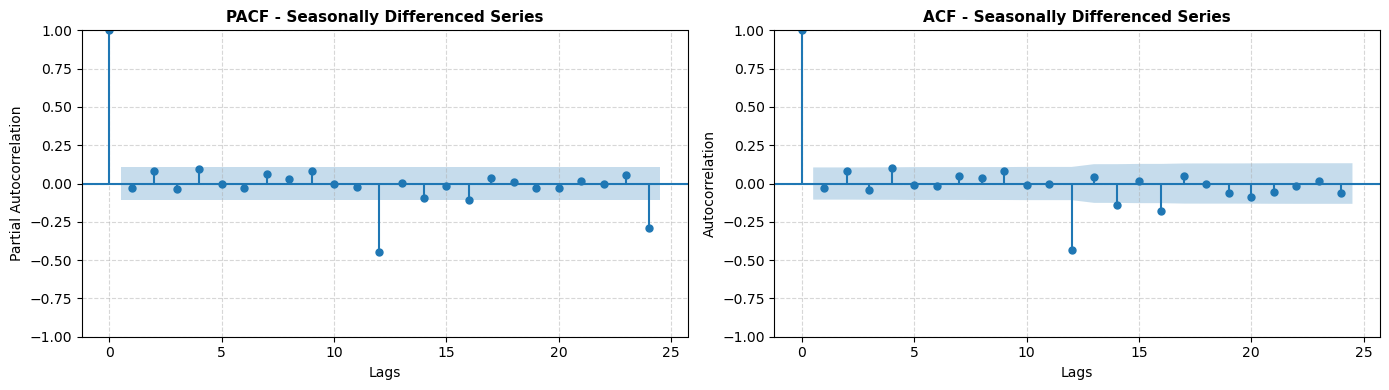

In [41]:
# ==========================================
# 2. PREPARATION (DIFFERENCING & IDENTIFICATION)
# ==========================================

print("--- Plotting Identification Diagnostics ---")

# Plot: ACF and PACF of the differenced series (Used to identify p and q for ARMA/ARIMA)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

# Partial Autocorrelation Function (PACF) -> Identifies AR order (p)
plot_pacf(monthly_wind_clean['Seasonally_Differenced'], lags=24, ax=axs[0])
axs[0].set_title('PACF - Seasonally Differenced Series', fontsize=11, fontweight='bold')
axs[0].set_xlabel('Lags')
axs[0].set_ylabel('Partial Autocorrelation')
axs[0].grid(True, linestyle='--', alpha=0.5)

# Autocorrelation Function (ACF) -> Identifies MA order (q)
plot_acf(monthly_wind_clean['Seasonally_Differenced'], lags=24, ax=axs[1])
axs[1].set_title('ACF - Seasonally Differenced Series', fontsize=11, fontweight='bold')
axs[1].set_xlabel('Lags')
axs[1].set_ylabel('Autocorrelation')
axs[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [42]:
# ==========================================
# 3. SPLIT: TRAIN AND TEST
# ==========================================

print("--- Confirming Train/Test Split Shapes ---")

# Informative prints to verify dataset structures before modeling
print(f"Training Series Shape (Seasonally Differenced): {train_series.shape}")
print(f"Testing Series Shape (Seasonally Differenced): {test_series.shape}")
print(f"Historical Baseline Shape (For Scale Reversion): {historical_baseline.shape}")
print(f"Ground Truth Test Shape (Actual Scale m/s): {test_actual_scale.shape}")

# Double-check date range alignment
print(f"\nTraining period: from {train_series.index[0].strftime('%Y-%m')} to {train_series.index[-1].strftime('%Y-%m')}")
print(f"Testing period:  from {test_series.index[0].strftime('%Y-%m')} to {test_series.index[-1].strftime('%Y-%m')}")

--- Confirming Train/Test Split Shapes ---
Training Series Shape (Seasonally Differenced): (312,)
Testing Series Shape (Seasonally Differenced): (36,)
Historical Baseline Shape (For Scale Reversion): (36,)
Ground Truth Test Shape (Actual Scale m/s): (36,)

Training period: from 1995-01 to 2020-12
Testing period:  from 2021-01 to 2023-12



--- Training Method 1: ARMA(2,0,2) ---
                                 SARIMAX Results                                  
Dep. Variable:     Seasonally_Differenced   No. Observations:                  312
Model:                     ARIMA(2, 0, 2)   Log Likelihood                -406.637
Date:                    Sun, 18 Oct 2026   AIC                            825.274
Time:                            00:25:17   BIC                            847.732
Sample:                        01-01-1995   HQIC                           834.250
                             - 12-01-2020                                         
Covariance Type:                      opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0069      0.050     -0.138      0.890      -0.105       0.091
ar.L1         -1.9022      0.033    -57.709      0.000     

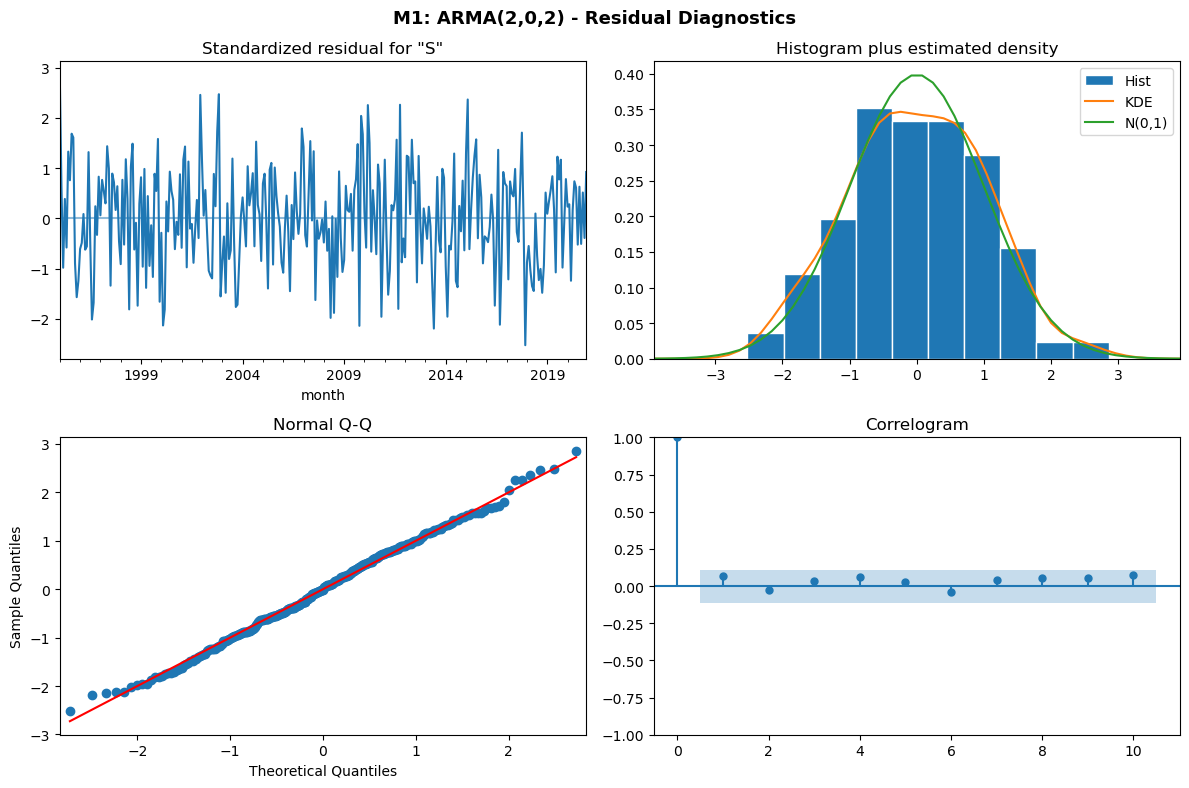

ARMA(2,0,2) Validation RMSE: 0.972 m/s


In [43]:
# ==========================================
# METHOD 1: ARMA MODEL (ARIMA with d=0)
# ==========================================
print("\n--- Training Method 1: ARMA(2,0,2) ---")

# Fitting the ARMA model on the 36-month training series
model_arma = ARIMA(train_series, order=(2, 0, 2))  
fit_arma = model_arma.fit()

# Printing model summary details
print(fit_arma.summary())

# ARMA Diagnostics (Plots Standardized Residuals, ACF, Histogram, and QQ-Plot)
fit_arma.plot_diagnostics(figsize=(12, 8))
plt.suptitle("M1: ARMA(2,0,2) - Residual Diagnostics", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ARMA Prediction for the 36-month validation horizon
pred_arma_summary = fit_arma.get_prediction(start=test_series.index[0], end=test_series.index[-1]).summary_frame()

# Reverting the seasonal differencing by adding the historical 36-month baseline
forecast_arma_actual = pred_arma_summary['mean'].values + historical_baseline.values

# Evaluating performance on actual scale (m/s)
rmse_arma = np.sqrt(mse(test_actual_scale, forecast_arma_actual))
print(f"ARMA(2,0,2) Validation RMSE: {rmse_arma:.3f} m/s")



--- Training Method 2: ARIMA(2,1,2) ---
                                 SARIMAX Results                                  
Dep. Variable:     Seasonally_Differenced   No. Observations:                  312
Model:                     ARIMA(2, 1, 2)   Log Likelihood                -408.969
Date:                    Sun, 18 Oct 2026   AIC                            827.938
Time:                            00:25:21   BIC                            846.637
Sample:                        01-01-1995   HQIC                           835.413
                             - 12-01-2020                                         
Covariance Type:                      opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9670      0.056    -17.160      0.000      -1.077      -0.857
ar.L2         -0.0424      0.056     -0.757      0.449    

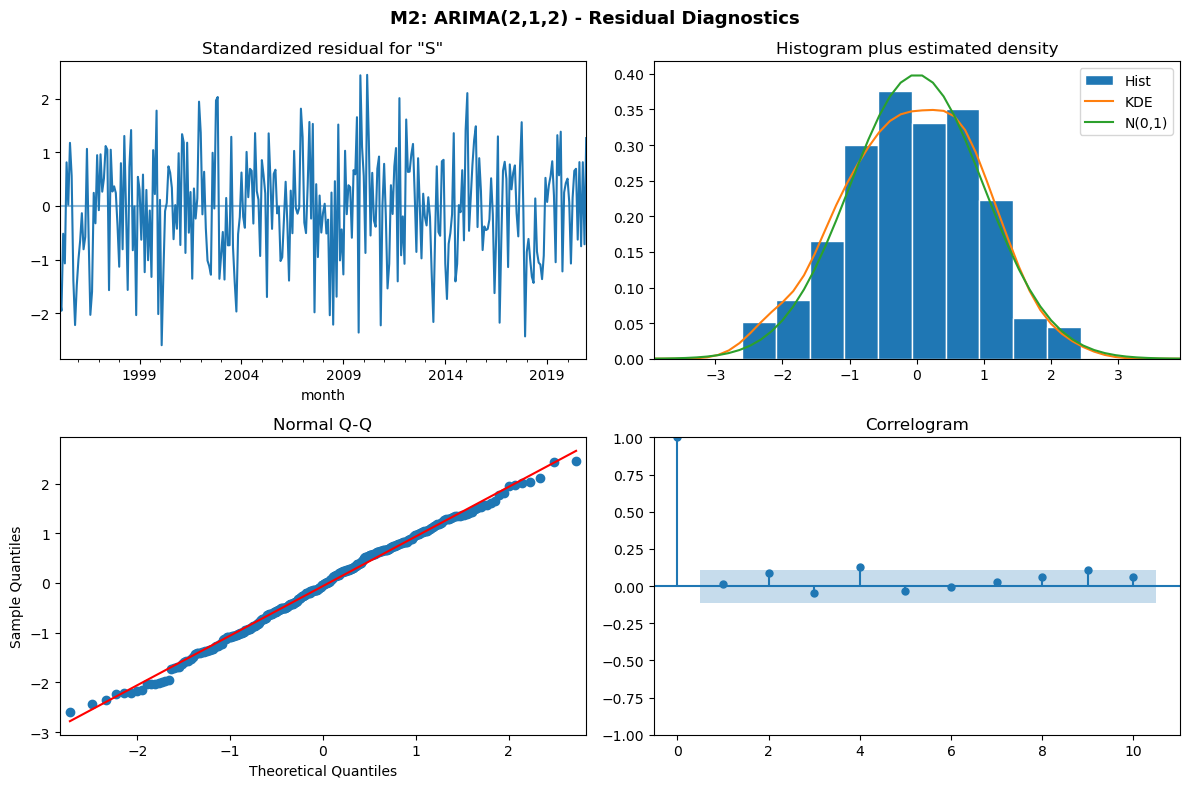

ARIMA(2,1,2) Validation RMSE: 0.990 m/s


In [44]:
# ==========================================
# METHOD 2: ARIMA MODEL (with d=1)
# ==========================================
print("\n--- Training Method 2: ARIMA(2,1,2) ---")

# Fitting the ARIMA model on the 36-month training series
model_arima = ARIMA(train_series, order=(2, 1, 2))  
fit_arima = model_arima.fit()

# Printing model summary details
print(fit_arima.summary())

# ARIMA Diagnostics (Plots Standardized Residuals, ACF, Histogram, and QQ-Plot)
fit_arima.plot_diagnostics(figsize=(12, 8))
plt.suptitle("M2: ARIMA(2,1,2) - Residual Diagnostics", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ARIMA Prediction for the 36-month validation horizon (FIXED START VALUE)
pred_arima_summary = fit_arima.get_prediction(start=test_series.index[0], end=test_series.index[-1]).summary_frame()

# Reverting the seasonal differencing by adding the historical 36-month baseline
forecast_arima_actual = pred_arima_summary['mean'].values + historical_baseline.values

# Evaluating performance on actual scale (m/s)
rmse_arima = np.sqrt(mse(test_actual_scale, forecast_arima_actual))
print(f"ARIMA(2,1,2) Validation RMSE: {rmse_arima:.3f} m/s")



--- Training Method 3: Deep LSTM ---
Epoch 1/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.1398 - val_loss: 0.0920
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1374 - val_loss: 0.0904
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1350 - val_loss: 0.0892
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1338 - val_loss: 0.0786
Epoch 5/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1334 - val_loss: 0.0738
Epoch 6/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1338 - val_loss: 0.0909
Epoch 7/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1296 - val_loss: 0.0744
Epoch 8/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1297 - val_loss: 0.0701
Epoch 9/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1292 - val_loss: 0.0708
Epoch 10/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1276 - val_loss: 0.0711
Epoch 11/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1256 - val_loss: 0.0716
Epoch 12/150
1

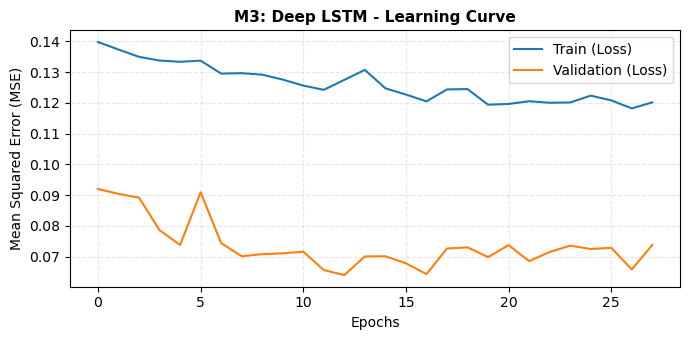


--- Validation Metrics (Actual Scale - m/s) ---
Deep LSTM Root Mean Squared Error (RMSE): 0.876 m/s


In [45]:
# ==========================================
# METHOD 3: DEEP LSTM MODEL
# ==========================================
print("\n--- Training Method 3: Deep LSTM ---")

# Extract underlying differenced data arrays
series_data = monthly_wind_clean[['Seasonally_Differenced']].values
train_size = len(monthly_wind_clean) - 36

# Explicitly defining train and test series for future timeline alignment
train_series = monthly_wind_clean['Seasonally_Differenced'][:-36]
test_series = monthly_wind_clean['Seasonally_Differenced'][-36:]

# Normalization
scaler = MinMaxScaler(feature_range=(-1, 1))
train_scaled = scaler.fit_transform(series_data[:train_size])
test_scaled = scaler.transform(series_data[train_size:])

# Sliding Windows Setup Function
def create_dataset(dataset, look_back=12):
    X, y = [], []
    for i in range(len(dataset) - look_back):
        X.append(dataset[i:(i + look_back), 0])
        y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(y)

look_back = 12
X_train, y_train = create_dataset(train_scaled, look_back)
inputs = np.vstack((train_scaled[-look_back:], test_scaled))
X_test, y_test = create_dataset(inputs, look_back)

# Reshape input to be [samples, timesteps, features] for the LSTM network
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

# Deep LSTM Architecture Specification
model_lstm = Sequential([
    LSTM(64, activation='tanh', input_shape=(look_back, 1), return_sequences=True),
    Dropout(0.2),
    LSTM(64, activation='tanh', return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

# Early Stopping Configuration
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=15,               
    restore_best_weights=True  
)

# Compiling the model
model_lstm.compile(optimizer='adam', loss='mse')

# Training Execution
history = model_lstm.fit(
    X_train, y_train, 
    epochs=150, 
    batch_size=16, 
    validation_split=0.1, 
    verbose=1,
    callbacks=[early_stop]
)     

# LSTM Diagnostics (Learning Curve Analysis)
plt.figure(figsize=(7, 3.5))
plt.plot(history.history['loss'], label='Train (Loss)', color='tab:blue')
plt.plot(history.history['val_loss'], label='Validation (Loss)', color='tab:orange')
plt.title('M3: Deep LSTM - Learning Curve', fontsize=11, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# LSTM PREDICTION & SCALE REVERSION
# ==========================================
# Generate predictions on the scaled test partition
lstm_pred_scaled = model_lstm.predict(X_test, verbose=0)
lstm_pred_diff = scaler.inverse_transform(lstm_pred_scaled).flatten()

# Retrieve the correct historical baseline from the resampled monthly series (shifted by 12 months)
historical_baseline = monthly_wind['wind_speed'].shift(12).loc[test_series.index]

# Both arrays now have a guaranteed aligned shape of (36,)
lstm_forecast_actual_scale = lstm_pred_diff + historical_baseline.values
test_actual_scale = monthly_wind['wind_speed'].loc[test_series.index].values

# Final Performance Evaluation
rmse_lstm = np.sqrt(mse(test_actual_scale, lstm_forecast_actual_scale))
print(f"\n--- Validation Metrics (Actual Scale - m/s) ---")
print(f"Deep LSTM Root Mean Squared Error (RMSE): {rmse_lstm:.3f} m/s")



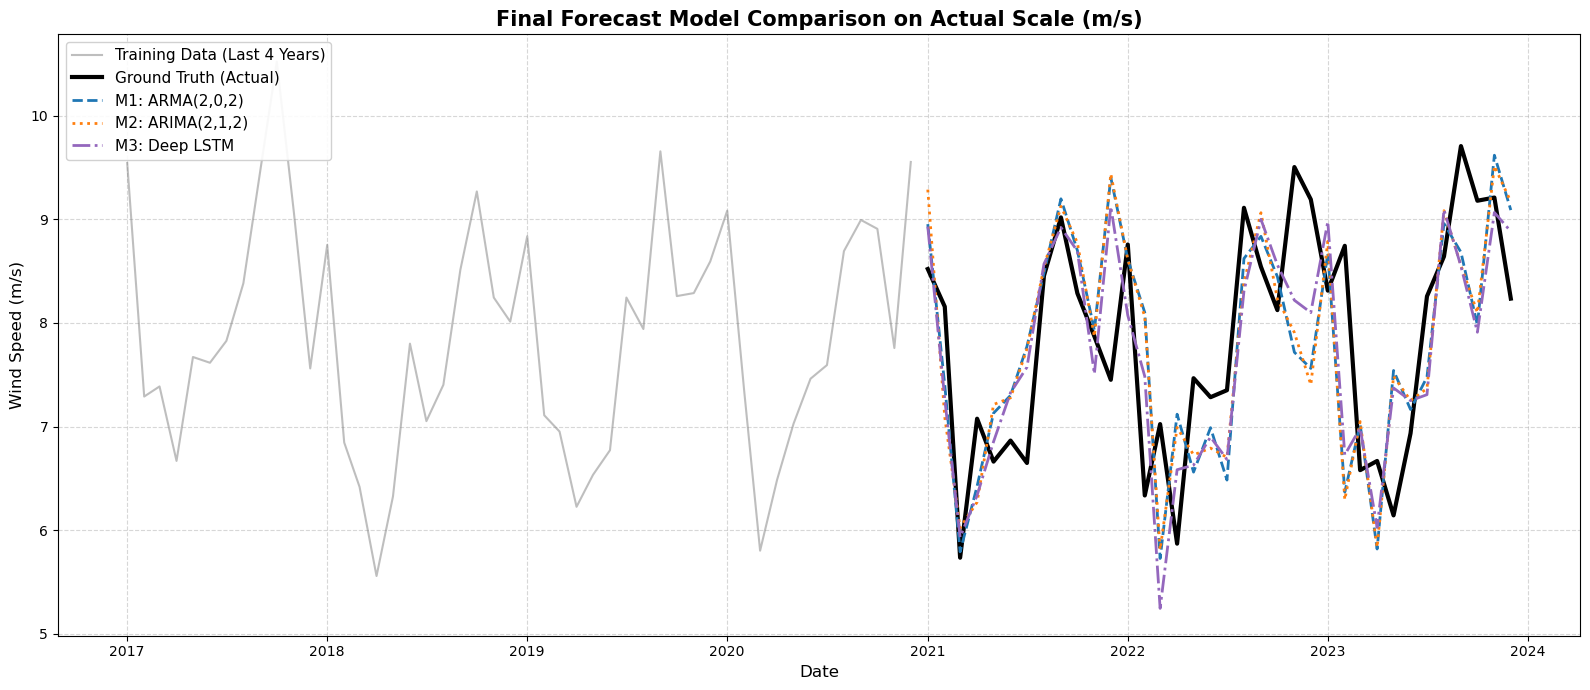

In [46]:
# ==========================================
# 4. FINAL VISUAL COMPARISON
# ==========================================
plt.figure(figsize=(16, 7))

# 4.1 Historical Context Window Setup
# Dynamically extracting the last 48 months of training data directly using the index
history_months = 48
historical_dates = train_series[-history_months:].index
# Padded to match the exact monthly resampled column scale
historical_values = monthly_wind['wind_speed'].loc[historical_dates].values

# 4.2 Plot Historical and Actual Ground Truth Data
plt.plot(historical_dates, historical_values, label='Training Data (Last 4 Years)', color='tab:gray', alpha=0.5, linewidth=1.5)
plt.plot(test_series.index, test_actual_scale, label='Ground Truth (Actual)', color='black', linewidth=3)

# 4.3 Plot Model Forecasts (All sharing the exact same test_series index layout)
plt.plot(test_series.index, forecast_arma_actual, label=f'M1: ARMA(2,0,2)', color='tab:blue', linestyle='--', linewidth=2)
plt.plot(test_series.index, forecast_arima_actual, label=f'M2: ARIMA(2,1,2)', color='tab:orange', linestyle=':', linewidth=2)
plt.plot(test_series.index, lstm_forecast_actual_scale, label=f'M3: Deep LSTM', color='tab:purple', linestyle='-.', linewidth=2)

# 4.4 Plot Labels and Formatting Customization
plt.title('Final Forecast Model Comparison on Actual Scale (m/s)', fontsize=15, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Wind Speed (m/s)', fontsize=12)
plt.legend(loc='upper left', fontsize=11, framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



In [47]:
# ==========================================
# 5. METRICS REPORT (RMSE)
# ==========================================
print("\n" + "="*50)
print("             PERFORMANCE COMPARISON (RMSE)")
print("       (Lower values indicate better accuracy)")
print("="*50)
print(f"Method 1: ARMA(2,0,2)   -> RMSE: {rmse_arma:.3f} m/s")
print(f"Method 2: ARIMA(2,1,2)  -> RMSE: {rmse_arima:.3f} m/s")
print(f"Method 3: Deep LSTM      -> RMSE: {rmse_lstm:.3f} m/s")
print("="*50)

# Storing evaluation results for automated model ranking
rmse_dict = {
    'M1: ARMA(2,0,2)': rmse_arma, 
    'M2: ARIMA(2,1,2)': rmse_arima, 
    'M3: Deep LSTM': rmse_lstm
}

# Finding the model configuration that minimizes Root Mean Squared Error
best_model = min(rmse_dict, key=rmse_dict.get)
print(f"\n>> The best performing model in the test period was: {best_model}")
print("="*50)



             PERFORMANCE COMPARISON (RMSE)
       (Lower values indicate better accuracy)
Method 1: ARMA(2,0,2)   -> RMSE: 0.972 m/s
Method 2: ARIMA(2,1,2)  -> RMSE: 0.990 m/s
Method 3: Deep LSTM      -> RMSE: 0.876 m/s

>> The best performing model in the test period was: M3: Deep LSTM
